In [1]:
pip install pandas numpy matplotlib seaborn jupyter

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# CartWise Commerce: Cart Abandonment Pattern Analysis

#Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
customers = pd.read_csv("cart_abandonment_customers.csv")
sessions = pd.read_csv("cart_abandonment_sessions.csv")

In [6]:
print("Customers shape:", customers.shape)
print("Sessions shape:", sessions.shape)

display(customers.head())
display(sessions.head())

Customers shape: (2500, 7)
Sessions shape: (10000, 14)


,customer_id,customer_segment,device_type,acquisition_channel,region,age_group,loyalty_member
0,CUST00001,Returning,Mobile,Organic Search,East,35-44,No
1,CUST00002,Returning,Desktop,Email,North,25-34,No
2,CUST00003,Loyal,Tablet,Direct,North,35-44,Yes
3,CUST00004,Returning,Desktop,Organic Search,South,45-54,Yes
4,CUST00005,New,Mobile,Organic Search,North,18-24,No


,session_id,customer_id,session_date,product_category,cart_value_inr,items_in_cart,discount_percent,shipping_cost_type,checkout_started,payment_method,checkout_duration_minutes,page_views,session_outcome,abandonment_reason
0,SESS000001,CUST02221,17-08-2026,Fashion,857.10,2,15,Paid,Yes,UPI,10.8,6,Abandoned,Website/Checkout Error
1,SESS000002,CUST01552,02-04-2026,Books,1644.79,6,0,Paid,Yes,Net Banking,6.9,7,Converted,Not Applicable
2,SESS000003,CUST01315,13-02-2026,Home & Kitchen,1581.59,4,15,Free,Yes,Debit Card,4.2,6,Abandoned,Website/Checkout Error
3,SESS000004,CUST01309,20-08-2026,Beauty,1731.22,4,25,Paid,No,Debit Card,0.0,5,Converted,Not Applicable
4,SESS000005,CUST01388,07-04-2026,Sports,1527.27,8,0,Free,No,Cash on Delivery,0.0,5,Abandoned,Unexpected Shipping Cost


In [7]:
#Inspect the data types
print("Customer columns and data types:")
print(customers.dtypes)

print("\nSession columns and data types:")
print(sessions.dtypes)

print("\nSession summary:")
sessions.info()

Customer columns and data types:
customer_id            str
customer_segment       str
device_type            str
acquisition_channel    str
region                 str
age_group              str
loyalty_member         str
dtype: object

Session columns and data types:
session_id                       str
customer_id                      str
session_date                     str
product_category                 str
cart_value_inr               float64
items_in_cart                  int64
discount_percent               int64
shipping_cost_type               str
checkout_started                 str
payment_method                   str
checkout_duration_minutes    float64
page_views                     int64
session_outcome                  str
abandonment_reason               str
dtype: object

Session summary:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                 

In [9]:
#Convert the session date to a proper datetime type
sessions["session_date"] = pd.to_datetime(
    sessions["session_date"],
    errors="coerce"
)

print(sessions["session_date"].min())
print(sessions["session_date"].max())

2026-01-01 00:00:00
2026-09-30 00:00:00


In [10]:
#Check missing values and duplicates
print("Missing values in customers:")
print(customers.isnull().sum())

print("\nMissing values in sessions:")
print(sessions.isnull().sum())

print(
    "\nDuplicate customer IDs:",
    customers["customer_id"].duplicated().sum()
)

print(
    "Duplicate session IDs:",
    sessions["session_id"].duplicated().sum()
)

Missing values in customers:
customer_id            0
customer_segment       0
device_type            0
acquisition_channel    0
region                 0
age_group              0
loyalty_member         0
dtype: int64

Missing values in sessions:
session_id                   0
customer_id                  0
session_date                 0
product_category             0
cart_value_inr               0
items_in_cart                0
discount_percent             0
shipping_cost_type           0
checkout_started             0
payment_method               0
checkout_duration_minutes    0
page_views                   0
session_outcome              0
abandonment_reason           0
dtype: int64

Duplicate customer IDs: 0
Duplicate session IDs: 0


In [16]:
#Validate values and join the tables
print("Session outcome counts:")
print(sessions["session_outcome"].value_counts())

print("\nInvalid cart values:")
print((sessions["cart_value_inr"] < 0).sum())

print("\nInvalid discount percentages:")
print(
    (~sessions["discount_percent"].between(0, 100)).sum()
)

print("\nUnmatched customer IDs:")
print(
    ~sessions["customer_id"].isin(
        customers["customer_id"]
    )
)

Session outcome counts:
session_outcome
Abandoned    5716
Converted    4284
Name: count, dtype: int64

Invalid cart values:
0

Invalid discount percentages:
0

Unmatched customer IDs:
0       False
1       False
2       False
3       False
4       False
        ...  
9995    False
9996    False
9997    False
9998    False
9999    False
Name: customer_id, Length: 10000, dtype: bool


In [14]:
#Join the datasets
df = sessions.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Merged dataset shape:", df.shape)
display(df.head())

Merged dataset shape: (10000, 20)


,session_id,customer_id,session_date,product_category,cart_value_inr,items_in_cart,discount_percent,shipping_cost_type,checkout_started,payment_method,checkout_duration_minutes,page_views,session_outcome,abandonment_reason,customer_segment,device_type,acquisition_channel,region,age_group,loyalty_member
0,SESS000001,CUST02221,2026-08-17,Fashion,857.10,2,15,Paid,Yes,UPI,10.8,6,Abandoned,Website/Checkout Error,New,Mobile,Organic Search,West,25-34,No
1,SESS000002,CUST01552,2026-04-02,Books,1644.79,6,0,Paid,Yes,Net Banking,6.9,7,Converted,Not Applicable,Returning,Desktop,Paid Search,West,25-34,No
2,SESS000003,CUST01315,2026-02-13,Home & Kitchen,1581.59,4,15,Free,Yes,Debit Card,4.2,6,Abandoned,Website/Checkout Error,New,Mobile,Email,South,25-34,No
3,SESS000004,CUST01309,2026-08-20,Beauty,1731.22,4,25,Paid,No,Debit Card,0.0,5,Converted,Not Applicable,New,Tablet,Paid Search,West,35-44,No
4,SESS000005,CUST01388,2026-04-07,Sports,1527.27,8,0,Free,No,Cash on Delivery,0.0,5,Abandoned,Unexpected Shipping Cost,New,Desktop,Organic Search,Central,35-44,No


In [17]:
#Calculate the key metrics
total_sessions = len(df)

abandoned_sessions = (
    df["session_outcome"] == "Abandoned"
).sum()

converted_sessions = (
    df["session_outcome"] == "Converted"
).sum()

abandonment_rate = (
    abandoned_sessions / total_sessions * 100
)

conversion_rate = (
    converted_sessions / total_sessions * 100
)

print("Total sessions:", total_sessions)
print("Abandoned sessions:", abandoned_sessions)
print("Converted sessions:", converted_sessions)
print(f"Abandonment rate: {abandonment_rate:.2f}%")
print(f"Conversion rate: {conversion_rate:.2f}%")

Total sessions: 10000
Abandoned sessions: 5716
Converted sessions: 4284
Abandonment rate: 57.16%
Conversion rate: 42.84%


,device_type,total_sessions,abandoned_sessions,abandonment_rate
1,Mobile,6277,3815,60.777441
0,Desktop,3094,1595,51.551390
2,Tablet,629,306,48.648649


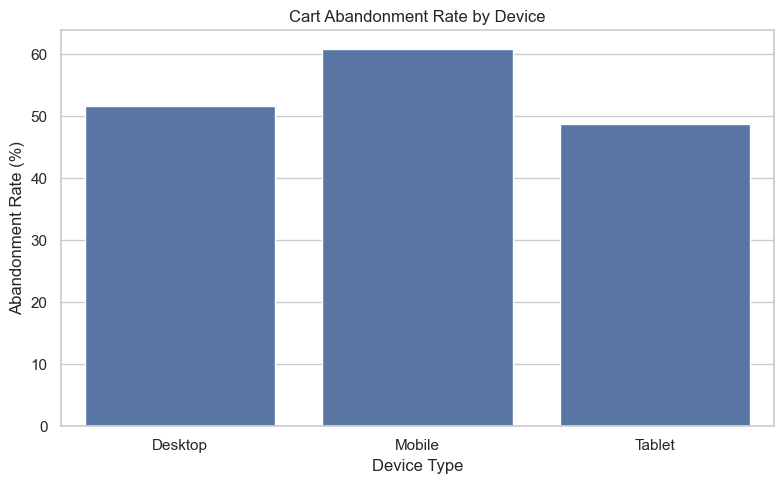

In [20]:
#Analyze abandonment by device
device_analysis = (
    df.assign(
        abandoned=df["session_outcome"].eq("Abandoned")
    )
    .groupby("device_type")
    .agg(
        total_sessions=("session_id", "count"),
        abandoned_sessions=("abandoned", "sum"),
        abandonment_rate=("abandoned", "mean")
    )
    .reset_index()
)

device_analysis["abandonment_rate"] *= 100

display(
    device_analysis.sort_values(
        "abandonment_rate",
        ascending=False
    )
)

#Visualize the result
plt.figure(figsize=(8, 5))

sns.barplot(
    data=device_analysis,
    x="device_type",
    y="abandonment_rate"
)

plt.title("Cart Abandonment Rate by Device")
plt.xlabel("Device Type")
plt.ylabel("Abandonment Rate (%)")
plt.tight_layout()
plt.show()

,product_category,total_sessions,abandoned_sessions,abandonment_rate
2,Electronics,1679,978,58.248958
3,Fashion,2785,1611,57.845601
4,Home & Kitchen,1814,1036,57.111356
5,Sports,1226,697,56.851550
1,Books,1061,603,56.833176
0,Beauty,1435,791,55.121951


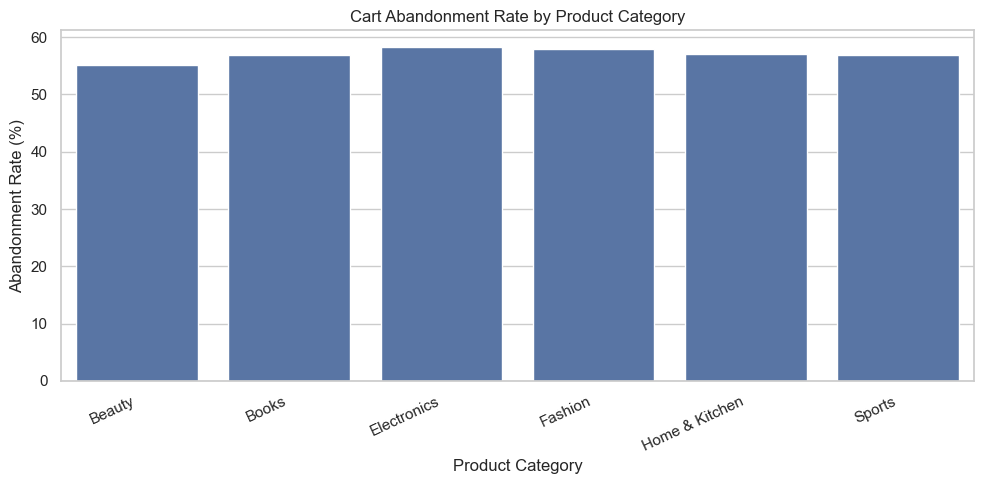

In [21]:
#Analyze product categories
category_analysis = (
    df.assign(
        abandoned=df["session_outcome"].eq("Abandoned")
    )
    .groupby("product_category")
    .agg(
        total_sessions=("session_id", "count"),
        abandoned_sessions=("abandoned", "sum"),
        abandonment_rate=("abandoned", "mean")
    )
    .reset_index()
)

category_analysis["abandonment_rate"] *= 100

display(
    category_analysis.sort_values(
        "abandonment_rate",
        ascending=False
    )
)

#Visualize the result
plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_analysis,
    x="product_category",
    y="abandonment_rate"
)

plt.title("Cart Abandonment Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Abandonment Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

,shipping_cost_type,total_sessions,abandoned_sessions,abandonment_rate
0,Free,5793,3093,53.392025
1,Paid,4207,2623,62.348467


,payment_method,total_sessions,abandoned_sessions,abandonment_rate
3,Net Banking,981,569,58.002039
2,Debit Card,1781,1024,57.495789
4,UPI,3192,1831,57.362155
1,Credit Card,1998,1142,57.157157
0,Cash on Delivery,1217,686,56.368118
5,Wallet,831,464,55.836342


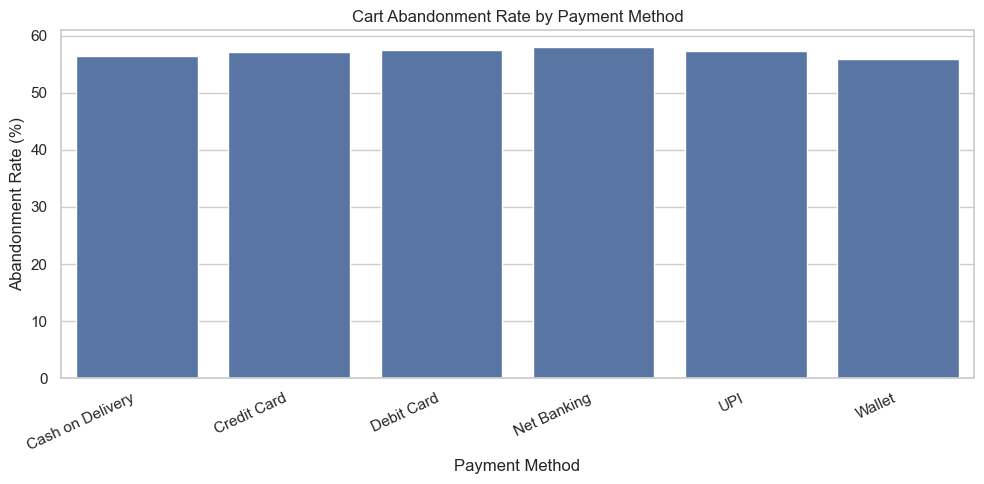

In [22]:
#Analyze shipping methods
shipping_analysis = (
    df.assign(
        abandoned=df["session_outcome"].eq("Abandoned")
    )
    .groupby("shipping_cost_type")
    .agg(
        total_sessions=("session_id", "count"),
        abandoned_sessions=("abandoned", "sum"),
        abandonment_rate=("abandoned", "mean")
    )
    .reset_index()
)

shipping_analysis["abandonment_rate"] *= 100
display(shipping_analysis)

#Analyze payment methods
payment_analysis = (
    df.assign(
        abandoned=df["session_outcome"].eq("Abandoned")
    )
    .groupby("payment_method")
    .agg(
        total_sessions=("session_id", "count"),
        abandoned_sessions=("abandoned", "sum"),
        abandonment_rate=("abandoned", "mean")
    )
    .reset_index()
)

payment_analysis["abandonment_rate"] *= 100

display(
    payment_analysis.sort_values(
        "abandonment_rate",
        ascending=False
    )
)

#Visualize the result
plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_analysis,
    x="payment_method",
    y="abandonment_rate"
)

plt.title("Cart Abandonment Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Abandonment Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

,abandonment_reason,abandoned_sessions,percentage
0,Unexpected Shipping Cost,1061,18.561931
1,Price Too High,942,16.480056
2,Payment Issue,796,13.925822
3,Website/Checkout Error,571,9.989503
4,Comparison Shopping,566,9.902029
5,Forced Account Creation,503,8.799860
6,Changed Mind,499,8.729881
7,Delivery Too Slow,481,8.414976
8,Other,297,5.195941


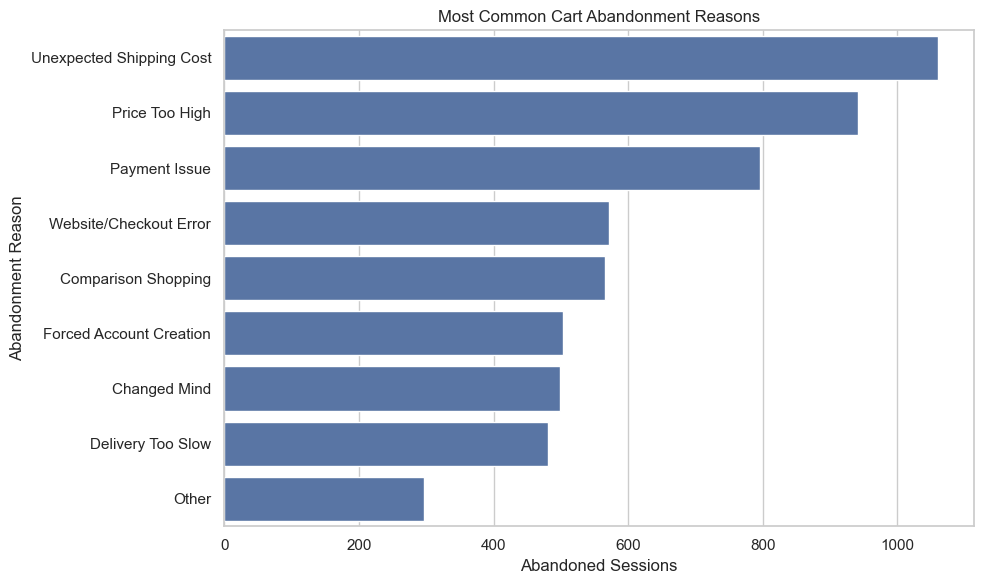

In [23]:
#Analyze abandonment reasons
reason_analysis = (
    df[df["session_outcome"] == "Abandoned"]
    ["abandonment_reason"]
    .value_counts()
    .rename_axis("abandonment_reason")
    .reset_index(name="abandoned_sessions")
)

reason_analysis["percentage"] = (
    reason_analysis["abandoned_sessions"]
    / reason_analysis["abandoned_sessions"].sum()
    * 100
)

display(reason_analysis)

#Visualize the result
plt.figure(figsize=(10, 6))

sns.barplot(
    data=reason_analysis,
    y="abandonment_reason",
    x="abandoned_sessions"
)

plt.title("Most Common Cart Abandonment Reasons")
plt.xlabel("Abandoned Sessions")
plt.ylabel("Abandonment Reason")
plt.tight_layout()
plt.show()

,month,total_sessions,abandoned_sessions,abandonment_rate
0,2026-01-01,1167,641,54.927164
1,2026-02-01,990,572,57.777778
2,2026-03-01,1127,667,59.183673
3,2026-04-01,1046,593,56.692161
4,2026-05-01,1146,669,58.376963
5,2026-06-01,1071,604,56.395892
6,2026-07-01,1164,671,57.646048
7,2026-08-01,1210,676,55.867769
8,2026-09-01,1079,623,57.738647


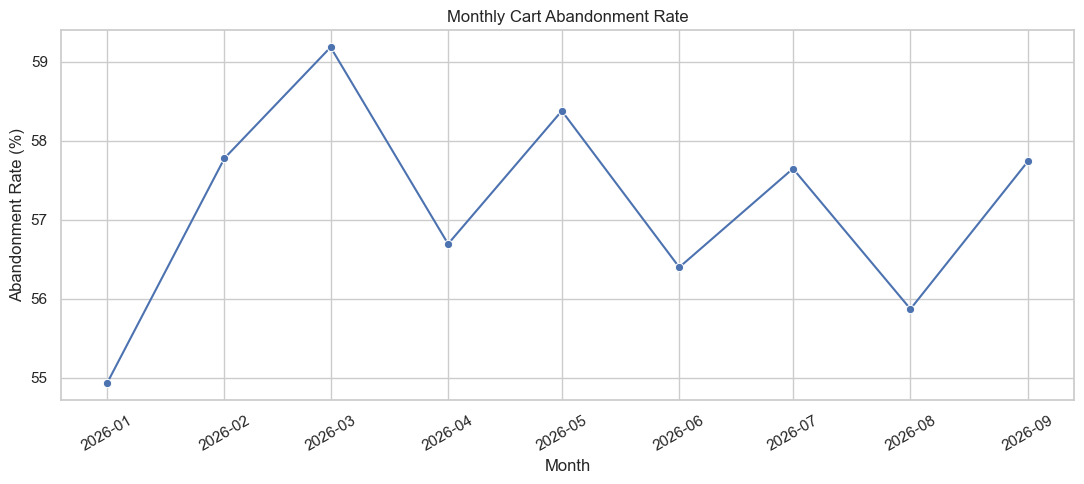

In [24]:
#Analyze monthly trends
df["month"] = (
    df["session_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_analysis = (
    df.assign(
        abandoned=df["session_outcome"].eq("Abandoned")
    )
    .groupby("month")
    .agg(
        total_sessions=("session_id", "count"),
        abandoned_sessions=("abandoned", "sum"),
        abandonment_rate=("abandoned", "mean")
    )
    .reset_index()
)

monthly_analysis["abandonment_rate"] *= 100

display(monthly_analysis)

#Visualize the result
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=monthly_analysis,
    x="month",
    y="abandonment_rate",
    marker="o"
)

plt.title("Monthly Cart Abandonment Rate")
plt.xlabel("Month")
plt.ylabel("Abandonment Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,cart_value_band,total_sessions,abandoned_sessions,abandonment_rate
0,"Under ₹1,000",2793,1629,58.324382
1,"₹1,000–₹2,999",5864,3314,56.514325
2,"₹3,000–₹4,999",1023,600,58.651026
3,"₹5,000–₹9,999",308,165,53.571429
4,"₹10,000+",12,8,66.666667


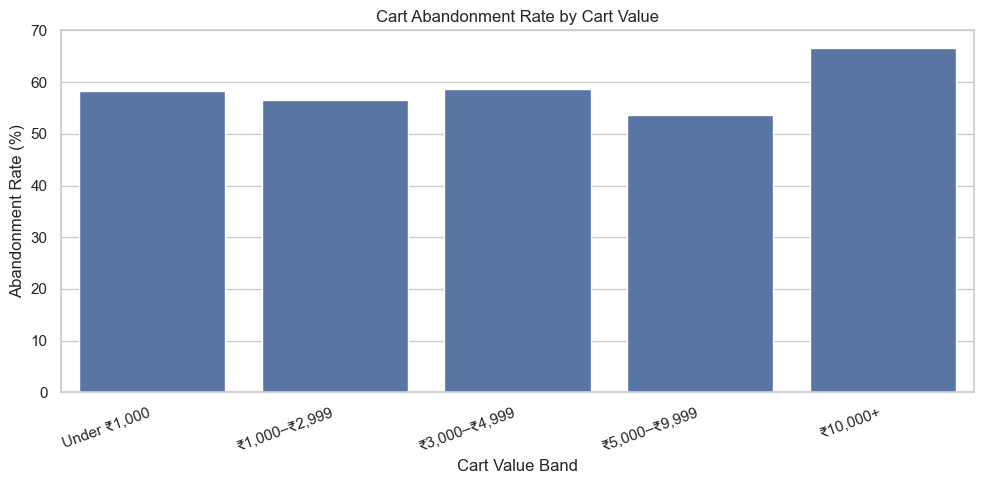

In [25]:
#Analyze cart value and discounts
df["cart_value_band"] = pd.cut(
    df["cart_value_inr"],
    bins=[0, 1000, 3000, 5000, 10000, np.inf],
    labels=[
        "Under ₹1,000",
        "₹1,000–₹2,999",
        "₹3,000–₹4,999",
        "₹5,000–₹9,999",
        "₹10,000+"
    ],
    right=False
)

cart_value_analysis = (
    df.assign(
        abandoned=df["session_outcome"].eq("Abandoned")
    )
    .groupby("cart_value_band", observed=False)
    .agg(
        total_sessions=("session_id", "count"),
        abandoned_sessions=("abandoned", "sum"),
        abandonment_rate=("abandoned", "mean")
    )
    .reset_index()
)

cart_value_analysis["abandonment_rate"] *= 100

display(cart_value_analysis)

#Visualize the result
plt.figure(figsize=(10, 5))

sns.barplot(
    data=cart_value_analysis,
    x="cart_value_band",
    y="abandonment_rate"
)

plt.title("Cart Abandonment Rate by Cart Value")
plt.xlabel("Cart Value Band")
plt.ylabel("Abandonment Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [28]:
#Save the analysis results
device_analysis.to_csv(
    "device_abandonment_analysis.csv",
    index=False
)

category_analysis.to_csv(
    "category_abandonment_analysis.csv",
    index=False
)

payment_analysis.to_csv(
    "payment_abandonment_analysis.csv",
    index=False
)

reason_analysis.to_csv(
    "abandonment_reason_analysis.csv",
    index=False
)

monthly_analysis.to_csv(
    "monthly_abandonment_analysis.csv",
    index=False
)
print("Final cleaned datasets exported successfully.")

Final cleaned datasets exported successfully.
